<a href="https://colab.research.google.com/github/hero55-svg/MODEL-FOR-PIMA-INDIAN-DIABETES-DATASET-/blob/main/Pima_Indian_Databse_Diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import numpy as np
import pandas as pd
import kagglehub
import os
import glob
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

path = kagglehub.dataset_download("raturisa/diabetes-processed-data-from-pima-indians")
print("Path to dataset files:", path)



csv_files = glob.glob(os.path.join(path, "*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No CSV file found in {path}")

dataset_file = csv_files[0]
print(f"Loading dataset from: {dataset_file}")

df = pd.read_csv(dataset_file)
print("\nDataset Info:")
print(df.info())
print("\nFirst 5 Rows:")
print(df.head())

target_col = "Outcome" if "Outcome" in df.columns else df.columns[-1]

zero_suspect_cols = [
    c
    for c in ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
    if c in df.columns
]
for col in zero_suspect_cols:
    if (df[col] == 0).sum() > 0:
        df[col] = df[col].replace(0, np.nan)
        df[col] = df[col].fillna(df[col].median())

if df.isna().sum().sum() > 0:
    df = df.fillna(df.median(numeric_only=True))

X = df.drop(columns=[target_col])
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

dt_model = DecisionTreeClassifier(max_depth=4, criterion="gini", random_state=42)
dt_model.fit(X_train, y_train)

svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
svm_model.fit(X_train_scaled, y_train)

y_pred_dt = dt_model.predict(X_test)
y_pred_svm = svm_model.predict(X_test_scaled)

train_acc_dt = dt_model.score(X_train, y_train)
test_acc_dt = dt_model.score(X_test, y_test)

train_acc_svm = svm_model.score(X_train_scaled, y_train)
test_acc_svm = svm_model.score(X_test_scaled, y_test)

print("=" * 60)
print(f"Decision Tree  | Train Acc: {train_acc_dt:.3f} | Test Acc: {test_acc_dt:.3f} | F1: {f1_score(y_test, y_pred_dt):.3f}")
print(f"SVM Classifier | Train Acc: {train_acc_svm:.3f} | Test Acc: {test_acc_svm:.3f} | F1: {f1_score(y_test, y_pred_svm):.3f}")
print("=" * 60)

print("\n Decision Tree Classification Report ---")
print(classification_report(y_test, y_pred_dt))

print("\n--- SVM Classification Report ---")
print(classification_report(y_test, y_pred_svm))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

cm_dt = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Decision Tree Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

cm_svm = confusion_matrix(y_test, y_pred_svm)
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[1])
axes[1].set_title("SVM (RBF) Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

Using Colab cache for faster access to the 'diabetes-processed-data-from-pima-indians' dataset.
Path to dataset files: /kaggle/input/diabetes-processed-data-from-pima-indians
Loading dataset from: /kaggle/input/diabetes-processed-data-from-pima-indians/dataset_diperbaiki.csv

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    float64
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    float64
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    float64
 8   Outcome                   768 non-null    int64  


NameError: name 'plt' is not defined

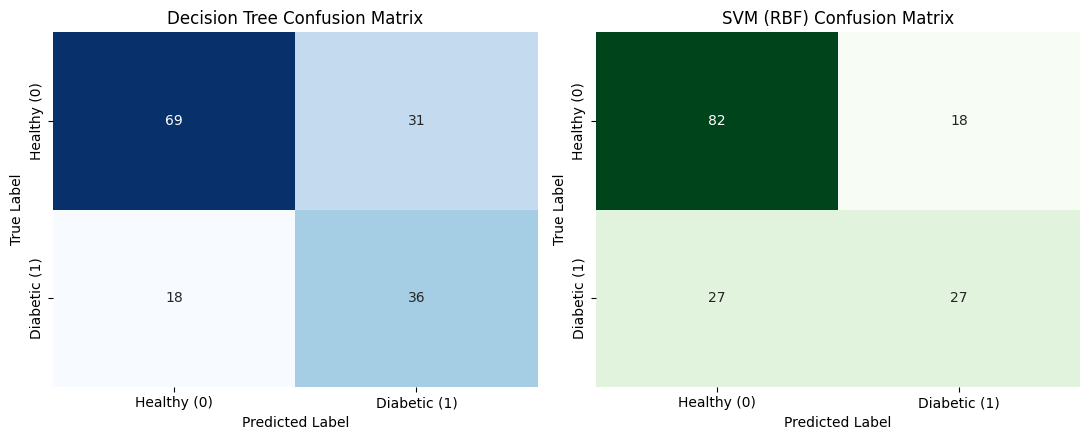

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

cm_dt = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[0],
    xticklabels=["Healthy (0)", "Diabetic (1)"],
    yticklabels=["Healthy (0)", "Diabetic (1)"],
)
axes[0].set_title("Decision Tree Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# SVM Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)
sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Greens",
    cbar=False,
    ax=axes[1],
    xticklabels=["Healthy (0)", "Diabetic (1)"],
    yticklabels=["Healthy (0)", "Diabetic (1)"],
)
axes[1].set_title("SVM (RBF) Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()